Fase 1: Análise Exploratória (EDA)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/manutencao_preditiva.csv")

print("Linhas e colunas:", df.shape)
print()
print(df.dtypes)

Linhas e colunas: (10000, 14)

udi                          int64
id_produto                  object
tipo                        object
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object


In [3]:
colunas_num = ["temperatura_ar_k", "temperatura_processo_k",
               "velocidade_rotacao_rpm", "torque_nm", "desgaste_ferramenta_min"]

df[colunas_num].describe()

,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min
count,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000
mean,300.002158,310.000895,1539.245263,39.974168,107.951000
std,2.001689,1.486432,180.273589,9.995453,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.100000,53.000000
50%,300.100000,310.100000,1504.000000,40.100000,108.000000
75%,301.500000,311.100000,1613.000000,46.700000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


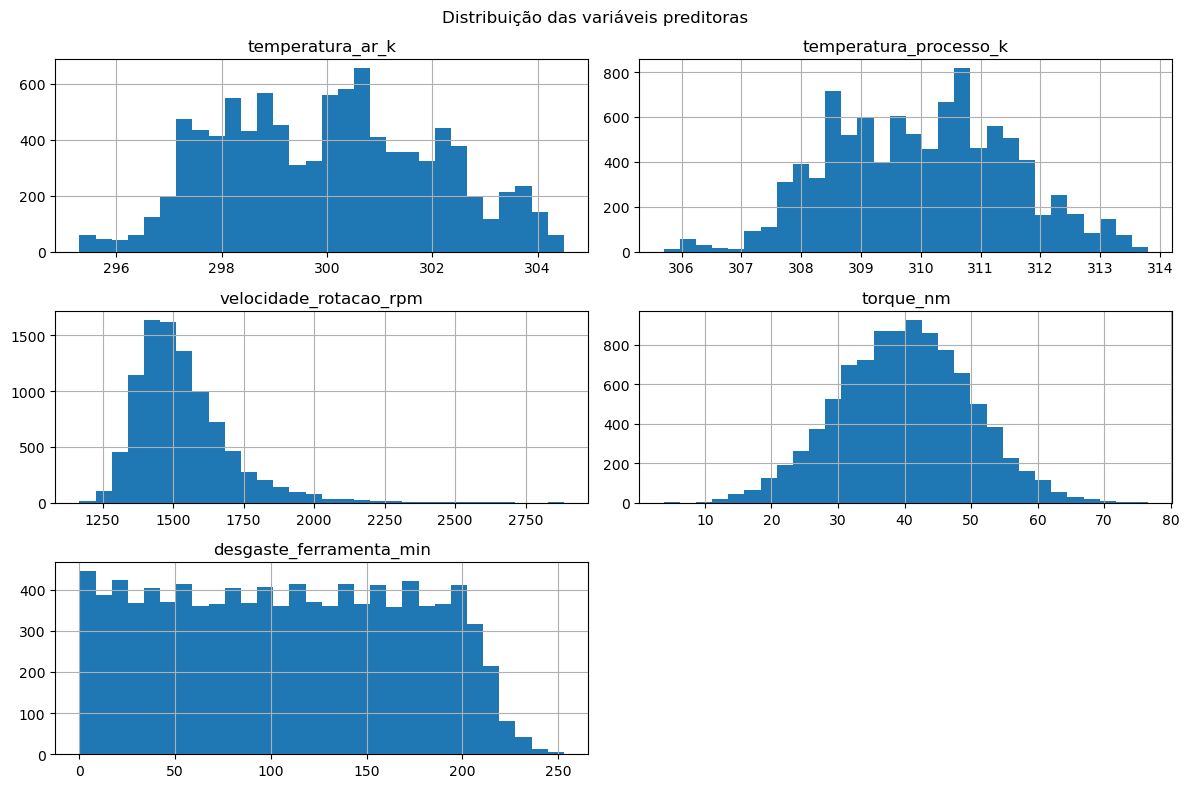

In [4]:
df[colunas_num].hist(bins=30, figsize=(12, 8))
plt.suptitle("Distribuição das variáveis preditoras")
plt.tight_layout()
plt.show()

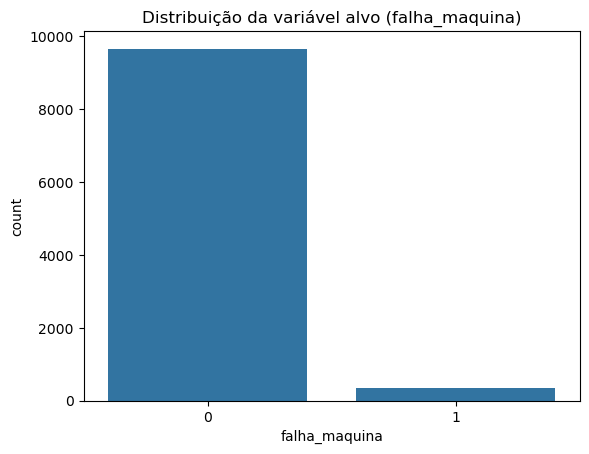

falha_maquina
0    96.61
1     3.39
Name: proportion, dtype: float64


In [5]:
ax = sns.countplot(x="falha_maquina", data=df)
ax.set_title("Distribuição da variável alvo (falha_maquina)")
plt.show()

print(df["falha_maquina"].value_counts(normalize=True).round(4) * 100)

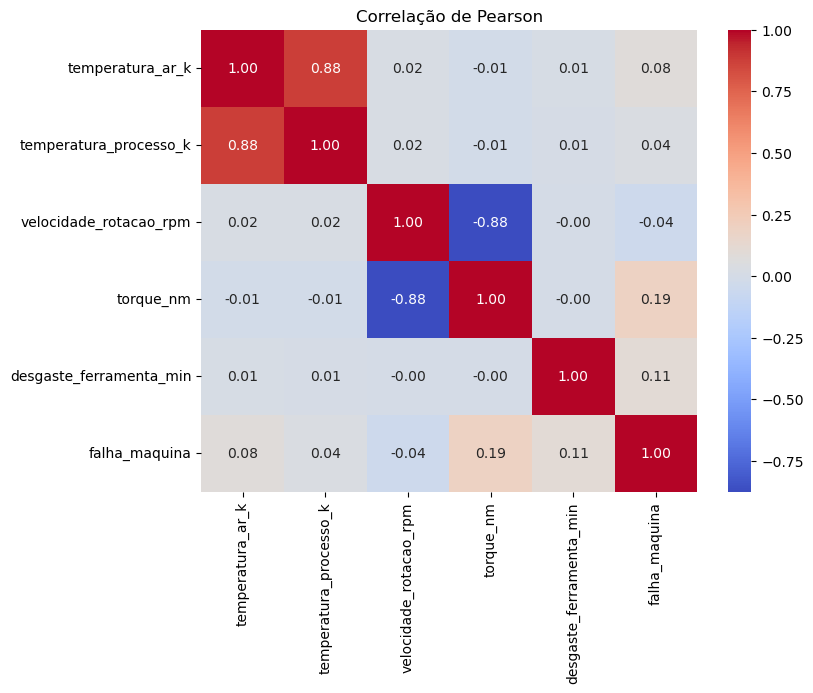

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[colunas_num + ["falha_maquina"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlação de Pearson")
plt.show()

## Análise da EDA

**Dimensões e tipos de dados.** A base tem 10.000 linhas e 14 colunas. As variáveis dos sensores (temperaturas, rotação, torque e desgaste) são numéricas. `tipo` e `id_produto` são texto. A variável alvo `falha_maquina` é binária (0 ou 1). As colunas `udi`, `id_produto` e `falha_*` (motivos da falha) não entram como preditoras: as duas primeiras só identificam o registro e as outras revelam o motivo da quebra, o que entregaria a resposta ao modelo (vazamento de dados).

**Valores ausentes.** No `describe()`, as quatro colunas de sensores (temperatura do ar, temperatura do processo, rotação e torque) têm `count` de 9.500, enquanto o desgaste da ferramenta tem 10.000. Ou seja, faltam 500 valores em cada uma das quatro colunas. Isso será tratado na Fase 2.

**Variável alvo.** Apenas 3,39% dos registros são falhas (339 de 10.000), e 96,61% são funcionamento normal. Um modelo que respondesse sempre "sem falha" acertaria 96,61% sem aprender nada. Por isso, só a acurácia não prova que um modelo é bom. Vou balancear apenas os dados de treino (Fase 4) e interpretar a acurácia com esse cuidado.

**Distribuições.**
- A rotação é assimétrica à direita: a maior parte fica entre 1.300 e 1.800 rpm, mas há uma cauda longa que chega a 2.886 rpm. A média (1.539) é maior que a mediana (1.504), puxada por esses valores altos. Por isso, vou usar a mediana, e não a média, para preencher os nulos dessa coluna.
- O torque tem formato próximo de uma curva normal, centrado em torno de 40 Nm.
- O desgaste da ferramenta é quase uniforme de 0 a 200 minutos e cai bem depois disso.
- As duas temperaturas têm distribuição irregular, sem formato de sino, e ocupam faixas estreitas (cerca de 295 a 305 K para o ar e 306 a 314 K para o processo).

**Correlações.** Com a variável alvo, todas as correlações são fracas: o torque tem 0,19, o desgaste 0,11, a temperatura do ar 0,08, a temperatura do processo 0,04 e a rotação -0,04. Isso mostra que nenhuma variável sozinha prevê a falha, e que o modelo vai depender da combinação delas. Entre as variáveis explicativas há dois pares muito correlacionados: temperatura do ar e temperatura do processo (0,88), e rotação e torque (-0,88). Isso significa que cada par carrega informação parecida. No KNN, que usa distância, essas variáveis acabam pesando mais do que deveriam. Já a árvore de decisão sofre menos com isso. A relação entre rotação e torque também me motivou a criar a variável `potencia` (rotação × torque) na Fase 3.

**Estratégia de modelagem que sai desta análise:** (1) tratar os 500 nulos com a mediana; (2) balancear só o treino, por causa dos 3,39% de falhas; (3) escalonar as variáveis para o KNN, que é sensível à escala; e (4) comparar os dois modelos pela acurácia no teste, sabendo que as correlações fracas limitam o desempenho.

Fase 2: Limpeza e Tratamento de Dados (Data Prep)

In [7]:
print("Duplicadas (linha inteira):", df.duplicated().sum())
print("Duplicadas (ignorando udi):", df.drop(columns="udi").duplicated().sum())

df = df.drop_duplicates()
print("Linhas após a remoção:", df.shape[0])

Duplicadas (linha inteira): 0
Duplicadas (ignorando udi): 0
Linhas após a remoção: 10000


In [8]:
colunas_sensores = ["temperatura_ar_k", "temperatura_processo_k",
                    "velocidade_rotacao_rpm", "torque_nm"]

print(df[colunas_sensores].isna().sum())

temperatura_ar_k          500
temperatura_processo_k    500
velocidade_rotacao_rpm    500
torque_nm                 500
dtype: int64


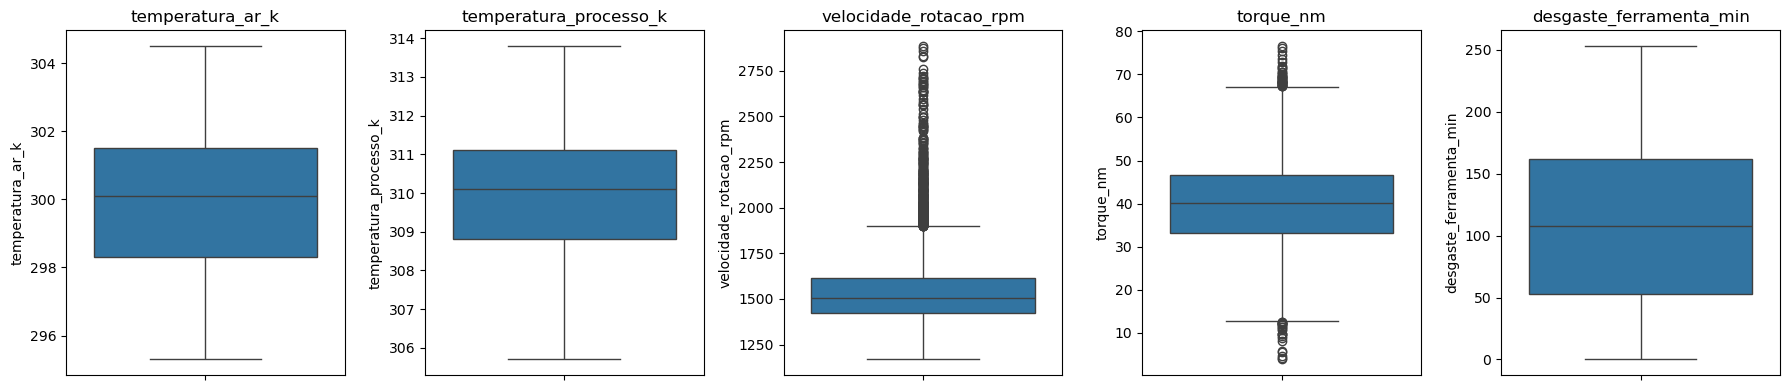

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, coluna in zip(axes, colunas_num):
    sns.boxplot(y=df[coluna], ax=ax)
    ax.set_title(coluna)
plt.tight_layout()
plt.show()

In [10]:
for coluna in colunas_sensores:
    df[coluna] = df[coluna].fillna(df[coluna].median())

print(df[colunas_sensores].isna().sum())

temperatura_ar_k          0
temperatura_processo_k    0
velocidade_rotacao_rpm    0
torque_nm                 0
dtype: int64


In [11]:
for coluna in ["velocidade_rotacao_rpm", "torque_nm"]:
    q1, q3 = df[coluna].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[coluna] < q1 - 1.5 * iqr) | (df[coluna] > q3 + 1.5 * iqr)).sum()
    print(coluna, "->", n, "outliers pelo critério do IQR")

velocidade_rotacao_rpm -> 465 outliers pelo critério do IQR
torque_nm -> 102 outliers pelo critério do IQR


**Duplicados.** Verifiquei as linhas duplicadas de duas formas: na linha inteira e ignorando a coluna `udi`. Fiz a segunda porque o `udi` é um identificador único e faria o primeiro teste sempre dar zero. Nos dois casos o resultado foi 0, então nenhuma linha foi removida e a base continuou com 10.000 registros.

**Valores ausentes.** As colunas `temperatura_ar_k`, `temperatura_processo_k`, `velocidade_rotacao_rpm` e `torque_nm` têm 500 valores ausentes cada (5% da base). O desgaste da ferramenta não tem nulos. Optei por preencher esses valores com a **mediana**, e não com a média, pelos seguintes motivos:
- A rotação é assimétrica à direita (histograma e boxplot), e os valores altos puxam a média para cima (1.539 contra 1.504 de mediana). A mediana não é afetada por esses extremos.
- Nas outras três colunas, a média e a mediana são quase iguais (por exemplo, 300,00 e 300,10 na temperatura do ar), então a mediana não prejudica essas colunas.
- Usando a mediana em todas, mantenho um único critério, mais simples de explicar e de reproduzir.

Depois da imputação, conferi que não restou nenhum valor ausente nas colunas de sensores.

**Limitação.** Os 500 valores ausentes estão nas mesmas linhas, ou seja, em cada um desses registros os quatro sensores falharam ao mesmo tempo. Preencher com a mediana faz esses registros parecerem máquinas "típicas", sem informação própria. Uma melhoria seria investigar por que os quatro sensores falham juntos, ou testar um modelo treinado sem essas linhas.

**Outliers.** Os boxplots mostram que as temperaturas e o desgaste não têm outliers. Já a rotação tem muitos pontos acima de cerca de 1.900 rpm, indo até 2.886 rpm, e o torque tem pontos abaixo de cerca de 13 Nm e acima de cerca de 67 Nm. Contando pelo critério do IQR, a rotação tem 465 outliers e o torque tem 102. Esse cálculo foi feito depois da imputação pela mediana: como os 500 valores preenchidos se concentram no centro da distribuição, o IQR fica um pouco menor e o critério passa a marcar mais pontos do que marcaria só com os dados originais. Eu decidi **manter** esses valores, pelos seguintes motivos:
- Não há indicação de erro de medição: são valores fisicamente possíveis para a máquina, e a rotação alta combina com o torque baixo (a correlação entre os dois é de -0,88, vista na Fase 1).
- Remover esses registros poderia eliminar justamente situações extremas de operação, que podem estar ligadas às falhas que quero prever.
- A árvore de decisão não é sensível a outliers, porque divide os dados por limites.

Isso tem um custo que vou acompanhar: o KNN e o StandardScaler são mais sensíveis a valores extremos, então os outliers podem influenciar o resultado do KNN na Fase 5 e na Fase 6.

Fase 3: Feature Engineering

In [12]:
df["potencia"] = df["velocidade_rotacao_rpm"] * df["torque_nm"]

print(df[["velocidade_rotacao_rpm", "torque_nm", "potencia"]].head())

   velocidade_rotacao_rpm  torque_nm  potencia
0                  1551.0       42.8   66382.8
1                  1408.0       46.3   65190.4
2                  1498.0       49.4   74001.2
3                  1504.0       40.1   60310.4
4                  1408.0       40.0   56320.0


In [13]:
print("Nulos em potencia:", df["potencia"].isna().sum())
print("Valores infinitos:", (df["potencia"] == float("inf")).sum())
print()
print(df["potencia"].describe())
print()
print("Correlação da potencia com a falha:",
      round(df["potencia"].corr(df["falha_maquina"]), 3))
print("Correlação do torque com a falha:",
      round(df["torque_nm"].corr(df["falha_maquina"]), 3))

Nulos em potencia: 0
Valores infinitos: 0

count    10000.000000
mean     59970.673120
std       9951.344325
min      10966.800000
25%      53497.050000
50%      60310.400000
75%      66412.975000
max      99980.400000
Name: potencia, dtype: float64

Correlação da potencia com a falha: 0.169
Correlação do torque com a falha: 0.184


In [14]:
faixas = pd.qcut(df["potencia"], q=10)
print(df.groupby(faixas, observed=True)["falha_maquina"].mean().round(3))

potencia
(10966.798999999999, 47228.64]    0.039
(47228.64, 51744.24]              0.007
(51744.24, 55040.71]              0.004
(55040.71, 57855.9]               0.008
(57855.9, 60310.4]                0.020
(60310.4, 61965.78]               0.010
(61965.78, 64804.34]              0.014
(64804.34, 68164.4]               0.030
(68164.4, 72656.63]               0.041
(72656.63, 99980.4]               0.161
Name: falha_maquina, dtype: float64


## Análise da Fase 3: Feature Engineering

**O que criei.** Criei a coluna `potencia = velocidade_rotacao_rpm * torque_nm`. Fiz isso depois de preencher os valores ausentes com a mediana (Fase 2). Se eu tivesse criado antes, cada linha com rotação ou torque ausente herdaria NaN na nova coluna.

**Por que essa combinação.** Na Fase 1 vi que rotação e torque têm correlação de -0,88: quando uma sobe, a outra tende a cair. Em um motor, a potência depende justamente do produto entre torque e rotação, então a nova variável resume as duas em uma medida que tem sentido físico. A escala do resultado é "rpm vezes Nm" e não watts. Para virar watts seria preciso converter rpm em rad/s, mas isso só multiplicaria a coluna por uma constante e não mudaria o comportamento dos modelos, além de o StandardScaler (Fase 5) normalizar a escala de qualquer forma.

**Validação.** A coluna tem 10.000 valores, com 0 nulos e 0 infinitos, variando de cerca de 10.967 a 99.980, com mediana de 60.310. A criação não gerou erro nem valores inválidos.

**Resultado.** A correlação de Pearson da `potencia` com a falha é 0,169, um pouco menor que a do torque sozinho (0,184). Esse valor do torque é diferente dos 0,19 da Fase 1 porque, na Fase 1, as 500 linhas com valor ausente eram ignoradas no cálculo, e agora elas entram preenchidas com a mediana. Ou seja, a `potencia` não tem correlação linear maior que o torque, e eu não vou afirmar que ela melhora o modelo só por isso. Mantive a variável porque ela é a combinação que o enunciado sugere e tem sentido físico. A correlação linear não captura relações em forma de "U", e a falha por potência, segundo as anotações da Engenharia, ocorre tanto por falta quanto por excesso. Para entender essa correlação baixa, dividi a `potencia` em 10 faixas com o mesmo número de registros e calculei a taxa de falha em cada uma. A faixa de maior potência (acima de cerca de 72.657) tem 16,1% de falhas, contra 3,39% na base inteira, e a de menor potência tem 3,9%. Já as faixas do meio ficam entre 0,4% e 2,0%. Ou seja, a relação tem formato de "U", com o lado do excesso de potência bem mais forte que o da falta. Como a correlação de Pearson só mede relação em linha reta, ela subestima o poder da variável. Esse padrão favorece a árvore de decisão, que consegue criar limites (por exemplo, "potência acima de X") e capturar relações que não são lineares. Vou verificar nas Fases 6 e 7 se isso se confirma no desempenho dos modelos.

Fase 4: Divisão e Balanceamento dos Dados

In [15]:
# Codifica o tipo (L < M < H tem ordem natural)
df["tipo"] = df["tipo"].map({"L": 0, "M": 1, "H": 2})

# Variáveis preditoras: sem udi, id_produto e sem as colunas falha_* (motivos da falha)
colunas_X = ["temperatura_ar_k", "temperatura_processo_k", "velocidade_rotacao_rpm",
             "torque_nm", "desgaste_ferramenta_min", "potencia", "tipo"]

X = df[colunas_X]
y = df["falha_maquina"]

print("X:", X.shape, "| y:", y.shape)

X: (10000, 7) | y: (10000,)


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Falhas no treino:", round(y_train.mean() * 100, 2), "%")
print("Falhas no teste: ", round(y_test.mean() * 100, 2), "%")

Treino: (8000, 7) | Teste: (2000, 7)
Falhas no treino: 3.39 %
Falhas no teste:  3.4 %


In [17]:
from imblearn.over_sampling import SMOTENC

smote = SMOTENC(categorical_features=[colunas_X.index("tipo")], random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

# Recalcula a potência para ficar coerente com a rotação e o torque sintéticos
X_train_bal["potencia"] = X_train_bal["velocidade_rotacao_rpm"] * X_train_bal["torque_nm"]

print("Treino antes: ", y_train.value_counts().to_dict())
print("Treino depois:", y_train_bal.value_counts().to_dict())
print("Teste (intocado):", y_test.value_counts().to_dict())

Treino antes:  {0: 7729, 1: 271}
Treino depois: {0: 7729, 1: 7729}
Teste (intocado): {0: 1932, 1: 68}


## Análise da Fase 4: Divisão e Balanceamento

**Preparação.** Antes de dividir, transformei a coluna `tipo` em número (L=0, M=1, H=2), porque os modelos só aceitam variáveis numéricas e as classes têm uma ordem natural. Essa troca é fixa e não usa informação dos dados, então não causa vazamento. O X tem 7 variáveis: as quatro de sensores, o desgaste, a `potencia` e o `tipo`. Deixei de fora o `udi` e o `id_produto` (só identificam o registro) e as colunas `falha_*`, que indicam o motivo da quebra e entregariam a resposta ao modelo.

**Divisão.** Separei 80% para treino (8.000 linhas) e 20% para teste (2.000 linhas), com `stratify=y`. Isso mantém a proporção de falhas em torno de 3,39% nos dois conjuntos (271 falhas no treino e 68 no teste). Sem a estratificação, o teste poderia ficar com poucas falhas por acaso, e a acurácia ficaria ainda menos confiável.

**Balanceamento.** Apliquei o SMOTENC **somente no treino**, depois da divisão. O SMOTENC é uma variante do SMOTE que também trata colunas categóricas: ele cria falhas sintéticas interpolando entre falhas reais vizinhas, e mantém o `tipo` em 0, 1 ou 2. Com isso o treino passou a ter 7.729 registros de cada classe. Se eu balanceasse antes de dividir, registros sintéticos feitos a partir de dados do teste vazariam para o treino (Data Leakage), e a acurácia no teste ficaria artificialmente alta. O conjunto de teste continua com a proporção real, de 3,39% de falhas, que é a situação que o modelo vai encontrar na fábrica.

**Ajuste na `potencia`.** O SMOTE interpola cada coluna separadamente, então a `potencia` sintética deixaria de ser igual à rotação vezes o torque. Por isso recalculei a coluna depois do balanceamento.

**Limitação.** As falhas sintéticas são combinações de apenas 271 falhas reais. O modelo pode aprender padrões dessas falhas específicas, e o ganho nas métricas pode parecer maior do que seria com dados novos.

Fase 5: Escalonamento de Variáveis (StandardScaler)

Fase 6: Ajuste de Parâmetros e Combate ao Overfitting

Fase 7: Avaliação da Acurácia e Veredito Final